In [1]:
# imports
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, precision_score, mean_absolute_error, mean_squared_error

In [2]:
# load data
df = pd.read_csv("data/titanic.csv")

# describe
df.describe()





,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Interpretation der statistischen Kennzahlen auf Basis der bereitgestellten Datensätze
- 891 Datensätze für Passagiere
- von einer kleinen Teilmenge von Passagieren ist das Alter unbekannt (ca. 177)
- ca. 38% haben tatsächlich überlebt
- Die meisten Passagiere fahren mit Klasse 3
- Durchschnittsalter ca. 30 Jahre
- Die meisten Passagiere kommen ohne Familienangehörige, ca. 60%
- Die Passagiere bezahlen durchschnittlich 32 {currency} für ihr Ticket
- 1,6% Passagiere hätten nicht bezahlt
- Alle Babys unter einem Jahr haben überlebt




In [19]:
import sqlite3

# In-Memory-Datenbank anlegen und df als Tabelle hineinschreiben
con = sqlite3.connect(":memory:")
df.to_sql("df", con, index=False, if_exists="replace")

# SQL ausführen und Ergebnis als DataFrame holen
pd.read_sql_query("""
SELECT COUNT(*) AS anzahl, Pclass
FROM df
GROUP BY Pclass
ORDER BY Pclass
""", con)

,anzahl,Pclass
0,216,1
1,184,2
2,491,3


In [7]:
df = pd.read_csv("data/titanic.csv")

# Überlebensrate nach Klasse

<Axes: xlabel='Pclass', ylabel='Survived'>

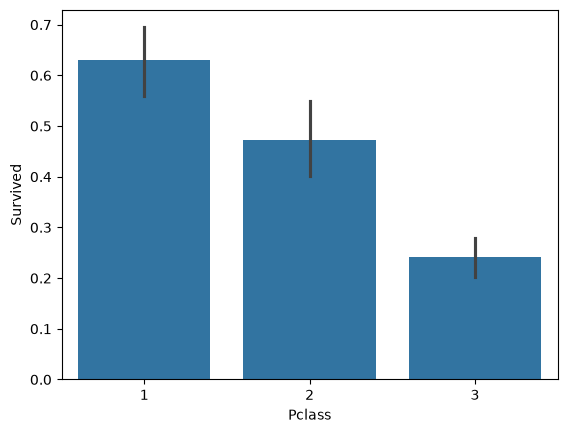

In [8]:
sns.barplot(data=df, x="Pclass", y="Survived")

# Überlebensrate geordnet nach Altersgruppe

<Axes: xlabel='AgeGroup', ylabel='Survived'>

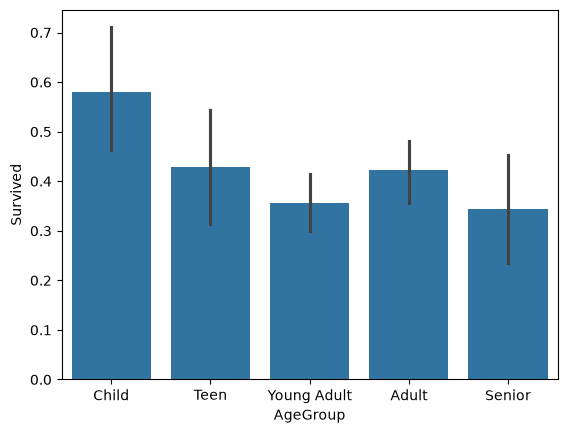

In [9]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 30, 50, 100],
                        labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
sns.barplot(data=df, x="AgeGroup", y="Survived")

# Überlebensrate nach Geschlecht

<Axes: xlabel='Sex', ylabel='Survived'>

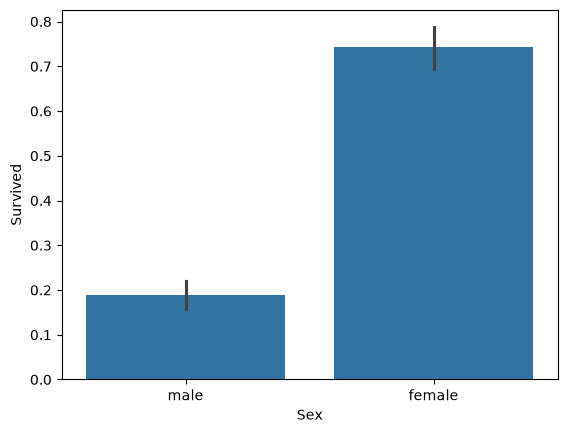

In [10]:
sns.barplot(data=df, x="Sex",  y="Survived")

# Überlebensrate nach Familiengröße

<Axes: xlabel='FamilySize', ylabel='Survived'>

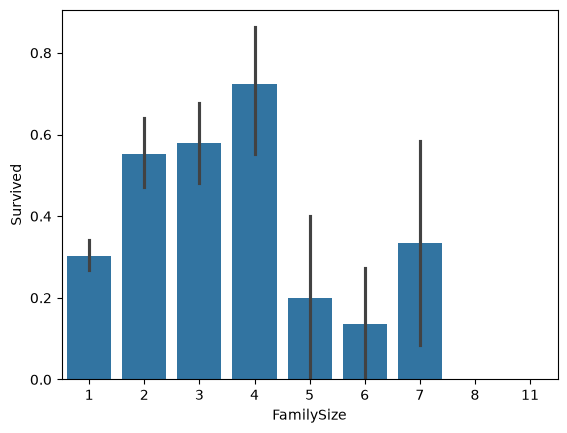

In [11]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
sns.barplot(data=df, x="FamilySize", y="Survived")

In [12]:
df = pd.read_csv("data/titanic.csv")

#Ausgewählte Features
X = [['Sex'], ['Fare']]
y = ['Survived']

df['PassengerId'] = df['PassengerId'].astype(str)
id_encoded = pd.get_dummies(df, columns=['PassengerId'], dtype=int)

print(id_encoded.head())

   Survived  Pclass                                               Name  \
0         0       3                            Braund, Mr. Owen Harris   
1         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...   
2         1       3                             Heikkinen, Miss. Laina   
3         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)   
4         0       3                           Allen, Mr. William Henry   

      Sex   Age  SibSp  Parch            Ticket     Fare Cabin  ...  \
0    male  22.0      1      0         A/5 21171   7.2500   NaN  ...   
1  female  38.0      1      0          PC 17599  71.2833   C85  ...   
2  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN  ...   
3  female  35.0      1      0            113803  53.1000  C123  ...   
4    male  35.0      0      0            373450   8.0500   NaN  ...   

  PassengerId_90  PassengerId_91  PassengerId_92  PassengerId_93  \
0              0               0               0            

In [13]:
# load data from csv
df = pd.read_csv("data/titanic.csv")


In [14]:
# features
X = df[['Sex', 'Fare', 'Age', 'Pclass']].copy()
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X['Age'] = X['Age'].fillna(X['Age'].median())

# target
y = df["Survived"]

In [15]:
# split training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# choose models
models = [
    LinearRegression(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    GradientBoostingRegressor(),
    SVR(),
]

results = {}

for model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_class = y_pred >= 0.5   # survived if prediction >= 0.5
    results[type(model).__name__] = {
        "Accuracy": accuracy_score(y_test, y_pred_class),
        "Precision": precision_score(y_test, y_pred_class),
        "Mean Absolute Error": mean_absolute_error(y_test, y_pred),
        "Mean Squared Error": mean_squared_error(y_test, y_pred),
    }

results = pd.DataFrame(results).T
results


,Accuracy,Precision,Mean Absolute Error,Mean Squared Error
LinearRegression,0.787709,0.757143,0.287746,0.137168
DecisionTreeRegressor,0.754190,0.678571,0.260486,0.244114
RandomForestRegressor,0.787709,0.750000,0.244238,0.152462
GradientBoostingRegressor,0.810056,0.822581,0.257216,0.131899
SVR,0.648045,0.739130,0.360203,0.243960


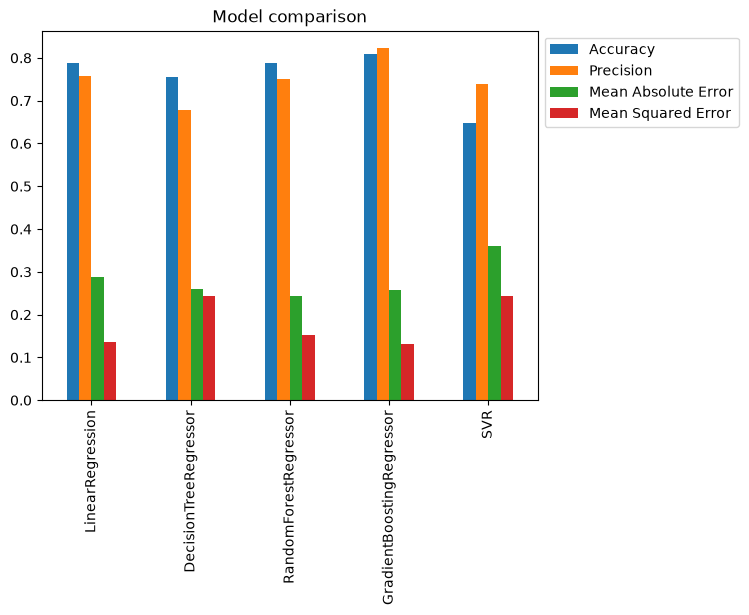

In [16]:
# compare models
results.plot.bar()
plt.title("Model comparison")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()


In [ ]:
df = pd.read_csv("data/titanic.csv")

df.loc[df['Sex'] == "male", 'Sex'] = "0"
df.loc[df['Sex'] == "female", 'Sex'] = "1"

X = df[['Sex', 'Fare', 'Age']]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rfc = RandomForestClassifier()

#rfc.fit(X_train, y_train)
#y_pred = rfc.predict(X_test)
#accuracy = accuracy_score(y_test, y_pred)

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 10, 12],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid = GridSearchCV(
    estimator=rfc,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(f"Beste Param: {grid.best_params_}")
print(f"Bester CV: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
best_acc = best_model.score(X_test, y_test)

print(f"Acc: {best_acc:.4f}")

Beste Param: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_split': 10, 'n_estimators': 500}
Bester CV: 0.8006
Acc: 0.7709
